**Hospital Activity Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
import json
from pathlib import Path
import joblib

In [2]:
df = pd.read_csv("/content/Hospital Activity.csv")

In [3]:
df.head()

,quarter_date,quarter_name,hb_code,hb_name,loc_code,loc_name,measure,specialty,spec_name,eps,los,avlos
0,31/12/2020,Oct - Dec-20,S08000015,NHS Ayrshire & Arran,S08000015,NHS Ayrshire & Arran,Elective Inpatients,A1,General Medicine,20,49,2.450000
1,31/03/2021,Jan - Mar-21,S08000015,NHS Ayrshire & Arran,S08000015,NHS Ayrshire & Arran,Elective Inpatients,A1,General Medicine,12,41,3.416667
2,30/06/2021,Apr - Jun-21,S08000015,NHS Ayrshire & Arran,S08000015,NHS Ayrshire & Arran,Elective Inpatients,A1,General Medicine,18,89,4.944444
3,30/09/2021,Jul - Sep-21,S08000015,NHS Ayrshire & Arran,S08000015,NHS Ayrshire & Arran,Elective Inpatients,A1,General Medicine,13,33,2.538462
4,31/12/2021,Oct - Dec-21,S08000015,NHS Ayrshire & Arran,S08000015,NHS Ayrshire & Arran,Elective Inpatients,A1,General Medicine,11,48,4.363636


General Medicine specialty regarding Elective Inpatients (patients whose admission was planned in advance):

• eps (Episodes) = 20: There were 20 completed patient journeys (episodes of care) during this three-month period.

• los (Length of Stay) = 49: These 20 patients spent a combined total of 49 days in the hospital.

• avlos (Average Length of Stay) = 2.45: On average, each elective inpatient stayed in the hospital for 2.45 days.


In [4]:
df["spec_name"].unique()

array(['General Medicine', 'Cardiology', 'Dermatology',
       'Endocrinology & Diabetes', 'Geriatric Medicine', 'Renal Medicine',
       'Rehabilitation Medicine', 'Respiratory Medicine', 'Rheumatology',
       'General Surgery', 'Anaesthetics', 'Ear, Nose & Throat (ENT)',
       'Ophthalmology', 'Trauma and Orthopaedic Surgery',
       'Plastic Surgery', 'Urology', 'Clinical Radiology', 'Haematology',
       'Gastroenterology', 'Medical Oncology', 'Palliative Medicine',
       'Clinical Oncology', 'Neurology', 'Infectious Diseases',
       'Cardiothoracic Surgery', 'Neurosurgery',
       'Intensive Care Medicine', 'Allergy', 'Immunology',
       'Clinical Neurophysiology', 'Clinical Genetics'], dtype=object)

In [5]:
df["spec_name"].value_counts()

,count
spec_name,
General Surgery,6294
Trauma and Orthopaedic Surgery,5646
General Medicine,5511
Urology,4804
Cardiology,4562
Respiratory Medicine,4151
Gastroenterology,4082
"Ear, Nose & Throat (ENT)",4011
Ophthalmology,4004


These numbers are not the total patients in each hospital. They may be in different hospitals or borders

In [6]:
df["quarter_date"].unique()

array(['31/12/2020', '31/03/2021', '30/06/2021', '30/09/2021',
       '31/12/2021', '31/03/2022', '30/06/2022', '30/09/2022',
       '31/12/2022', '31/03/2023', '30/06/2023', '30/09/2023',
       '31/12/2023', '31/03/2024', '30/06/2024', '30/09/2024',
       '31/12/2024', '31/03/2025', '30/06/2025', '30/09/2025',
       '31/12/2025'], dtype=object)

Every three months from the end of 2020 to the end of 2025

In [7]:
df.shape

(82573, 12)

take care those (82573) rows are not individual patients.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82573 entries, 0 to 82572
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   quarter_date  82573 non-null  object 
 1   quarter_name  82573 non-null  object 
 2   hb_code       82573 non-null  object 
 3   hb_name       82573 non-null  object 
 4   loc_code      82573 non-null  object 
 5   loc_name      82573 non-null  object 
 6   measure       82573 non-null  object 
 7   specialty     82573 non-null  object 
 8   spec_name     82573 non-null  object 
 9   eps           82573 non-null  int64  
 10  los           82573 non-null  int64  
 11  avlos         72399 non-null  float64
dtypes: float64(1), int64(2), object(9)
memory usage: 7.6+ MB


We have nulls in (avlos) column

In [9]:
df.isnull().sum()

,0
quarter_date,0
quarter_name,0
hb_code,0
hb_name,0
loc_code,0
loc_name,0
measure,0
specialty,0
spec_name,0
eps,0


In [10]:
df["measure"].value_counts()

,count
measure,
All Inpatients and Day cases,17286
All Inpatients,15562
Transfers,13651
All Day cases,12901
Emergency Inpatients,12236
Elective Inpatients,10937


Elective Inpatients: Already planned to be admitted before.

Emergency Inpatients

Transfers	Episodes: Transfer patients between sections

All Inpatients

All Day cases: The everyday patients that are discharged.

All Inpatients and Day cases: Total impatients and day cases

In [11]:
df[
    ["hb_name", "loc_name"]
].drop_duplicates().head(15)

,hb_name,loc_name
0,NHS Ayrshire & Arran,NHS Ayrshire & Arran
223,NHS Ayrshire & Arran,University Hospital Ayr
364,NHS Ayrshire & Arran,University Hospital Crosshouse
516,NHS Borders,Borders General Hospital
631,NHS Borders,NHS Borders
746,NHS Dumfries & Galloway,Dumfries & Galloway Royal Infirmary
955,NHS Dumfries & Galloway,Galloway Community Hospital
974,NHS Dumfries & Galloway,NHS Dumfries & Galloway
1188,NHS Fife,NHS Fife
1478,NHS Fife,National Treatment Centre Fife Orthopaedics


hb >>> An NHS health board (or health authority) is a regional or national administrative organization responsible for planning, funding, and delivering healthcare services to a specific population within the National Health Service (NHS) in Scotland, Wales, or managing the overarching national framework in England.

loc >>> Actual hospital or board

In [12]:
df["quarter_date"] = pd.to_datetime(
    df["quarter_date"],
    format="%d/%m/%Y"
)

print(df["quarter_date"].dtype)
print(df["quarter_date"].min())
print(df["quarter_date"].max())

datetime64[ns]
2020-12-31 00:00:00
2025-12-31 00:00:00


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82573 entries, 0 to 82572
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   quarter_date  82573 non-null  datetime64[ns]
 1   quarter_name  82573 non-null  object        
 2   hb_code       82573 non-null  object        
 3   hb_name       82573 non-null  object        
 4   loc_code      82573 non-null  object        
 5   loc_name      82573 non-null  object        
 6   measure       82573 non-null  object        
 7   specialty     82573 non-null  object        
 8   spec_name     82573 non-null  object        
 9   eps           82573 non-null  int64         
 10  los           82573 non-null  int64         
 11  avlos         72399 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(8)
memory usage: 7.6+ MB


In [14]:
df.groupby("quarter_date").size()

,0
quarter_date,
2020-12-31,3909
2021-03-31,3835
2021-06-30,3946
2021-09-30,3926
2021-12-31,3991
2022-03-31,3985
2022-06-30,3982
2022-09-30,4015
2022-12-31,3942


This means that not every hospital or speciality have recorded data in each 21 quarters

In [15]:
coverage = df.groupby(
    ["loc_name", "spec_name"]
)["quarter_date"].nunique()

coverage.describe()

,quarter_date
count,1049.000000
mean,16.478551
std,7.308220
min,1.000000
25%,13.000000
50%,21.000000
75%,21.000000
max,21.000000


this means thtat we have some combinations only recorded in one quarter, but 75% of the combinations recorded in all the 21 quarters

In [16]:
coverage.value_counts().sort_index()

,count
quarter_date,
1,72
2,41
3,26
4,15
5,23
6,17
7,15
8,13
9,5


In [17]:
print("Health Boards:", df["hb_code"].nunique())
print("Locations:", df["loc_code"].nunique())
print("Specialties:", df["specialty"].nunique())

Health Boards: 18
Locations: 57
Specialties: 31


In [18]:
board_locations = df.loc[
    df["hb_code"] == df["loc_code"],
    ["hb_name", "loc_name"]
].drop_duplicates()

board_locations

,hb_name,loc_name
0,NHS Ayrshire & Arran,NHS Ayrshire & Arran
631,NHS Borders,NHS Borders
974,NHS Dumfries & Galloway,NHS Dumfries & Galloway
1188,NHS Fife,NHS Fife
2068,NHS Forth Valley,NHS Forth Valley
2754,NHS Grampian,NHS Grampian
3613,NHS Greater Glasgow & Clyde,NHS Greater Glasgow & Clyde
5767,NHS Highland,NHS Highland
6364,NHS Lanarkshire,NHS Lanarkshire
7063,NHS Lothian,NHS Lothian


The dataset contains 18 locations where hb_code == loc_code.

These include NHS Health Boards and other reporting entities, such as Scotland and Non-NHS Providers.

Matching codes alone does not prove that a record represents a hospital or an aggregate total. Reporting levels must be verified before aggregation.


In [19]:
other_locations = df.loc[
    df["hb_code"] != df["loc_code"],
    ["hb_name", "loc_code", "loc_name"]
].drop_duplicates()

other_locations

,hb_name,loc_code,loc_name
223,NHS Ayrshire & Arran,A210H,University Hospital Ayr
364,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse
516,NHS Borders,B120H,Borders General Hospital
746,NHS Dumfries & Galloway,Y146H,Dumfries & Galloway Royal Infirmary
955,NHS Dumfries & Galloway,Y144H,Galloway Community Hospital
1478,NHS Fife,F812H,National Treatment Centre Fife Orthopaedics
1490,NHS Fife,F805H,Queen Margaret Hospital
1628,NHS Fife,F704H,Victoria Hospital
1881,NHS Forth Valley,V217H,Forth Valley Royal Hospital
2255,NHS Grampian,N101H,Aberdeen Royal Infirmary


In [20]:
df[df["avlos"].isna()][["eps", "los", "avlos"]].head(10)

,eps,los,avlos
42,0,5,NaN
43,0,0,NaN
44,0,0,NaN
45,0,0,NaN
46,0,0,NaN
47,0,0,NaN
48,0,0,NaN
49,0,0,NaN
50,0,5,NaN
51,0,5,NaN


In [21]:
df.loc[df["avlos"].isna(), "eps"].value_counts()

,count
eps,
0,10174


avlos = los/eps

In [22]:
df.loc[df["eps"] == 0, "avlos"].notna().sum()

np.int64(0)

This means that every avlos empty means that the eps is empty

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
keys = [
    "quarter_date",
    "hb_code",
    "loc_code",
    "specialty",
    "measure"
]

df.duplicated(subset=keys).sum()

np.int64(0)

**Hospital Beds Dataset**

In [25]:
beds_df= pd.read_csv("/content/Hospital Beds.csv")

In [26]:
beds_df.head()

,quarter_date,quarter_name,hb_code,hb_name,loc_code,loc_name,spec_name,aasb,tobd,asb,aob,p_occ
0,31/12/2020,Oct - Dec-20,S08000015,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Accident & Emergency,6,6,0.065217,0.065217,100.0
1,31/12/2020,Oct - Dec-20,S08000015,NHS Ayrshire & Arran,A210H,University Hospital Ayr,Accident & Emergency,36,36,0.391304,0.391304,100.0
2,31/12/2020,Oct - Dec-20,S08000015,NHS Ayrshire & Arran,S08000015,NHS Ayrshire & Arran,Accident & Emergency,42,42,0.456522,0.456522,100.0
3,31/03/2021,Jan - Mar-21,S08000015,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Accident & Emergency,6,6,0.066667,0.066667,100.0
4,31/03/2021,Jan - Mar-21,S08000015,NHS Ayrshire & Arran,A210H,University Hospital Ayr,Accident & Emergency,34,34,0.377778,0.377778,100.0


• aasb: Quarterly Available Staffed Bed Days >>> The total number of staffed beds that were available for use over the course of a quarter.

• tobd: Quarterly Occupied Bed Days >>> The total number of days those beds were actually occupied by patients over the quarter.

• asb: Daily Average Available Staffed Beds >>> The average number of staffed beds available per day.

• aob: Daily Average Occupied Beds >>> The average number of beds occupied by patients per day.

• p_occ: Percentage (%) Occupancy >>> The proportion of available beds that were occupied, calculated as a percentage.

asb = aasb/ Days in quarter

aob = tobd/Days in quarter

p_occ = (tobd/aasb) *100 = (aob/asb)*100

In [27]:
beds_df.shape

(29930, 12)

In [28]:
beds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29930 entries, 0 to 29929
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   quarter_date  29930 non-null  object 
 1   quarter_name  29930 non-null  object 
 2   hb_code       29930 non-null  object 
 3   hb_name       29930 non-null  object 
 4   loc_code      29930 non-null  object 
 5   loc_name      29930 non-null  object 
 6   spec_name     29930 non-null  object 
 7   aasb          29930 non-null  int64  
 8   tobd          29930 non-null  int64  
 9   asb           29930 non-null  float64
 10  aob           29930 non-null  float64
 11  p_occ         29877 non-null  float64
dtypes: float64(3), int64(2), object(7)
memory usage: 2.7+ MB


In [29]:
beds_df["quarter_date"] = pd.to_datetime(
    beds_df["quarter_date"],
    format="%d/%m/%Y"
)

print("Date range:")
print(beds_df["quarter_date"].min())
print(beds_df["quarter_date"].max())
print("Quarters:", beds_df["quarter_date"].nunique())

Date range:
2020-12-31 00:00:00
2025-12-31 00:00:00
Quarters: 21


In [30]:
beds_df.loc[
    beds_df["p_occ"].isna(),
    ["aasb", "tobd", "asb", "aob", "p_occ"]
].head(10)

,aasb,tobd,asb,aob,p_occ
2483,0,0,0.0,0.0,NaN
2484,0,0,0.0,0.0,NaN
2485,0,0,0.0,0.0,NaN
2486,0,0,0.0,0.0,NaN
2489,0,0,0.0,0.0,NaN
2490,0,0,0.0,0.0,NaN
2493,0,0,0.0,0.0,NaN
2494,0,0,0.0,0.0,NaN
2497,0,0,0.0,0.0,NaN
2498,0,0,0.0,0.0,NaN


In [31]:
missing_occ = beds_df[beds_df["p_occ"].isna()]
print("Missing occupancy:", len(missing_occ))
print("All missing occupancy has zero available bed-days:", (missing_occ["aasb"] == 0).all())
print("All missing occupancy has zero occupied bed-days:", (missing_occ["tobd"] == 0).all())
print("Exact duplicates:", beds_df.duplicated().sum())
print("Duplicate quarter + board + location + specialty:", beds_df.duplicated(subset=["quarter_date", "hb_code", "loc_code", "spec_name"]).sum())

Missing occupancy: 53
All missing occupancy has zero available bed-days: True
All missing occupancy has zero occupied bed-days: True
Exact duplicates: 0
Duplicate quarter + board + location + specialty: 0


Missing occupancy is undefined when available bed-days = 0. We should not replace it with 0%.

In [32]:
print("Locations:", beds_df["loc_code"].nunique())
print("Specialties:", beds_df["spec_name"].nunique())
print("Quarters:", beds_df["quarter_date"].nunique())
print("Rows with board code = location code:", (beds_df["hb_code"] == beds_df["loc_code"]).sum())
print(beds_df["p_occ"].describe())
print("Locations: ", df["loc_code"].nunique())
print("Specialties: ", df["spec_name"].nunique())
print("Quarters: ", df["quarter_date"].nunique())
print("Rows with board code = location code:", (df["hb_code"] == df["loc_code"]).sum())

Locations: 54
Specialties: 76
Quarters: 21
Rows with board code = location code: 12534
count    29877.000000
mean        78.491020
std         27.733014
min          0.000000
25%         70.042668
50%         89.616402
75%        100.000000
max        100.000000
Name: p_occ, dtype: float64
Locations:  57
Specialties:  31
Quarters:  21
Rows with board code = location code: 32681


Board-level and hospital-level rows may overlap. For a hospital-focused model, use location-specific rows (`hb_code != loc_code`) and keep board-level reporting separate. This is a practical filtering rule, not a verified classification of every site.

Check zero capacity, extreme occupancy, arithmetic consistency, and repeated keys. An occupancy of 100% is not automatically an outlier.

In [33]:
beds_audit = pd.DataFrame({
    "metric": ["Zero available bed-days", "Missing occupancy", "0% occupancy", "100% occupancy", "Exact duplicates", "Repeated business keys"],
    "rows": [(beds_df["aasb"] == 0).sum(), beds_df["p_occ"].isna().sum(),
             (beds_df["p_occ"] == 0).sum(), (beds_df["p_occ"] == 100).sum(),
             beds_df.duplicated().sum(),
             beds_df.duplicated(["quarter_date", "hb_code", "loc_code", "spec_name"]).sum()]
})
display(beds_audit)

,metric,rows
0,Zero available bed-days,53
1,Missing occupancy,53
2,0% occupancy,1027
3,100% occupancy,8668
4,Exact duplicates,0
5,Repeated business keys,0


In [34]:
valid_capacity = beds_df["aasb"] > 0
occupancy_difference = (
    beds_df.loc[valid_capacity, "p_occ"] -
    100 * beds_df.loc[valid_capacity, "tobd"] / beds_df.loc[valid_capacity, "aasb"]
).abs()
print("Occupancy formula mismatches (> 0.01 percentage points):", (occupancy_difference > .01).sum())
print("Missing occupancy and zero capacity:", ((beds_df["p_occ"].isna()) & (beds_df["aasb"] == 0)).sum())
print("Occupied bed-days exceed available bed-days:", (beds_df["tobd"] > beds_df["aasb"]).sum())

Occupancy formula mismatches (> 0.01 percentage points): 0
Missing occupancy and zero capacity: 53
Occupied bed-days exceed available bed-days: 0


**Beds — Why 100% Occupancy Needs Capacity Context**

In [76]:
full_occ = beds_df.loc[beds_df["p_occ"] == 100].copy()
print("100% occupancy records:", len(full_occ))
print("Share of non-missing records (%):", round(100 * len(full_occ) / beds_df["p_occ"].notna().sum(), 2))
display(full_occ[["aasb", "asb", "tobd"]].describe())
display(full_occ.groupby(pd.cut(full_occ["asb"], bins=[-0.001, 1, 5, 20, 100, float("inf")], include_lowest=True),
                         observed=True).size().rename("rows"))

100% occupancy records: 8668
Share of non-missing records (%): 29.01


,aasb,asb,tobd
count,8668.000000,8668.000000,8668.000000
mean,237.444278,2.599557,237.444278
std,656.529636,7.187959,656.529636
min,1.000000,0.010870,1.000000
25%,3.000000,0.033333,3.000000
50%,18.000000,0.195652,18.000000
75%,126.000000,1.380435,126.000000
max,7457.000000,81.054348,7457.000000


,rows
asb,
"(-0.002, 1.0]",6140
"(1.0, 5.0]",1435
"(5.0, 20.0]",811
"(20.0, 100.0]",282


**Beds — Time Coverage and Reporting Consistency**

In [36]:
beds_series_keys = ["hb_code", "loc_code", "spec_name"]
beds_coverage = beds_df.groupby(beds_series_keys)["quarter_date"].nunique()
print("Location-specialty series:", len(beds_coverage))
print("Series with all 21 quarters:", (beds_coverage == 21).sum())
display(beds_coverage.describe())
display(beds_df.groupby("quarter_date").agg(rows=("loc_code", "size"), locations=("loc_code", "nunique"), specialties=("spec_name", "nunique")).tail(8))

Location-specialty series: 1889
Series with all 21 quarters: 1188


,quarter_date
count,1889.000000
mean,15.844362
std,7.660647
min,1.000000
25%,10.000000
50%,21.000000
75%,21.000000
max,21.000000


,rows,locations,specialties
quarter_date,,,
2024-03-31,1433,54,63
2024-06-30,1432,54,62
2024-09-30,1445,54,63
2024-12-31,1406,54,64
2025-03-31,1389,54,59
2025-06-30,1419,54,61
2025-09-30,1418,54,61
2025-12-31,1442,54,62


**Beds — Quarterly Occupancy by Capacity**

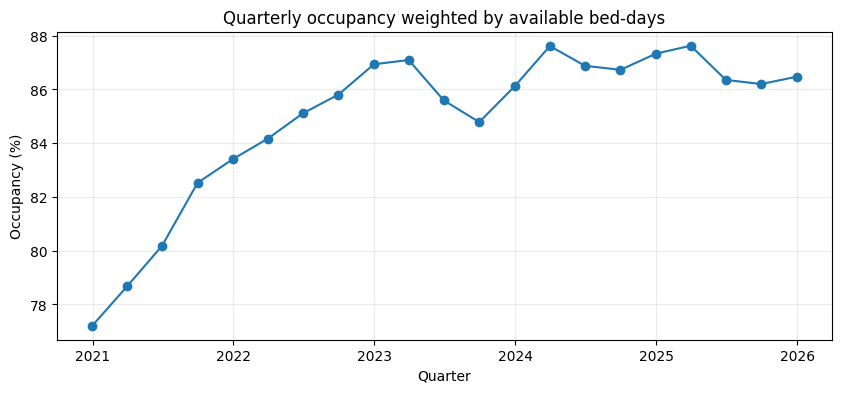

,quarter_date,aasb,tobd,weighted_occupancy
16,2024-12-31,5038182,4400034,87.333764
17,2025-03-31,5028731,4406587,87.628211
18,2025-06-30,4994992,4313507,86.356635
19,2025-09-30,5004737,4314202,86.202372
20,2025-12-31,5050316,4367291,86.475599


In [37]:
beds_trend = beds_df.loc[(beds_df["hb_code"] != beds_df["loc_code"]) & (beds_df["aasb"] > 0)].groupby("quarter_date", as_index=False)[["aasb", "tobd"]].sum()
beds_trend["weighted_occupancy"] = 100 * beds_trend["tobd"] / beds_trend["aasb"]
plt.figure(figsize=(10, 4))
plt.plot(beds_trend["quarter_date"], beds_trend["weighted_occupancy"], marker="o")
plt.title("Quarterly occupancy weighted by available bed-days")
plt.xlabel("Quarter")
plt.ylabel("Occupancy (%)")
plt.grid(alpha=.25)
plt.show()
display(beds_trend.tail())

We retain legitimate 0% and 100% occupancy records. Undefined occupancy remains missing, and rows without a valid target are excluded only where the model requires a numeric label. The code-equality reporting filter is provisional and needs official site classification.

**Hospital Waiting Dataset**

In [68]:
waiting_df = pd.read_csv("/content/Hospital Waiting.csv")

In [69]:
waiting_df.head()

,MonthEnding,HBT,HBTQF,PatientType,WaitType,Specialty,SpecialtyQF,Waits,WaitsQF,WaitsOver12Weeks,...,WaitsOver52Weeks,WaitsOver52WeeksQF,WaitsOver78Weeks,WaitsOver78WeeksQF,WaitsOver104Weeks,WaitsOver104WeeksQF,Median,MedianQF,90thPercentile,90thPercentileQF
0,20250228,S92000003,d,New Outpatient,Completed,Z9,d,103575.0,NaN,40593.0,...,9865.0,NaN,2760.0,NaN,598.0,NaN,48.0,NaN,360.0,NaN
1,20260228,S92000003,d,New Outpatient,Completed,Z9,d,112377.0,NaN,46666.0,...,9250.0,NaN,2460.0,NaN,536.0,NaN,51.0,NaN,344.0,NaN
2,20250430,S92000003,d,New Outpatient,Completed,Z9,d,103576.0,NaN,35284.0,...,8333.0,NaN,2253.0,NaN,543.0,NaN,43.0,NaN,342.0,NaN
3,20260430,S92000003,d,New Outpatient,Completed,Z9,d,103759.0,NaN,35873.0,...,3519.0,NaN,858.0,NaN,195.0,NaN,42.0,NaN,297.0,NaN
4,20250630,S92000003,d,New Outpatient,Completed,Z9,d,110949.0,NaN,40940.0,...,10278.0,NaN,2897.0,NaN,807.0,NaN,47.0,NaN,359.0,NaN


In [70]:
print("Shape:", waiting_df.shape)

Shape: (41030, 21)


In [73]:
print(waiting_df.isna().sum().sort_values(ascending=False).head(12))

WaitsOver104WeeksQF    39775
WaitsOver78WeeksQF     39775
WaitsOver52WeeksQF     39775
WaitsOver12WeeksQF     39775
WaitsQF                39775
SpecialtyQF            39231
HBTQF                  36081
MedianQF               32062
90thPercentileQF       32062
Median                  8968
90thPercentile          8968
Waits                   1255
dtype: int64


In [74]:
waiting_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41030 entries, 0 to 41029
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   MonthEnding          41030 non-null  int64  
 1   HBT                  41030 non-null  object 
 2   HBTQF                4949 non-null   object 
 3   PatientType          41030 non-null  object 
 4   WaitType             41030 non-null  object 
 5   Specialty            41030 non-null  object 
 6   SpecialtyQF          1799 non-null   object 
 7   Waits                39775 non-null  float64
 8   WaitsQF              1255 non-null   object 
 9   WaitsOver12Weeks     39775 non-null  float64
 10  WaitsOver12WeeksQF   1255 non-null   object 
 11  WaitsOver52Weeks     39775 non-null  float64
 12  WaitsOver52WeeksQF   1255 non-null   object 
 13  WaitsOver78Weeks     39775 non-null  float64
 14  WaitsOver78WeeksQF   1255 non-null   object 
 15  WaitsOver104Weeks    39775 non-null 

In [75]:
print("Patient types:", waiting_df["PatientType"].unique())
print("Wait types:", waiting_df["WaitType"].unique())

Patient types: ['New Outpatient' 'Inpatient/Day case']
Wait types: ['Completed' 'Ongoing']


Waiting data is monthly and organized by health board, patient type, wait type, and specialty code. Activity and beds are quarterly and have location-level rows. We should not merge these datasets by specialty name or quarter without checking definitions and matching granularity. QF fields are quality flags, not numerical outcomes.

In [40]:
waiting_df["MonthEnding"] = pd.to_datetime(waiting_df["MonthEnding"].astype(str), format="%Y%m%d")
print("Waiting range:", waiting_df["MonthEnding"].min(), "to", waiting_df["MonthEnding"].max())
print("Duplicate waiting keys:", waiting_df.duplicated(subset=["MonthEnding", "HBT", "PatientType", "WaitType", "Specialty"]).sum())
waiting_df.groupby(["PatientType", "WaitType"]).size()

Waiting range: 2024-08-31 00:00:00 to 2026-08-31 00:00:00
Duplicate waiting keys: 0


PatientType         WaitType 
Inpatient/Day case  Completed     7894
                    Ongoing       8556
New Outpatient      Completed    11985
                    Ongoing      12595
dtype: int64

The waiting dataset is useful for a separate board-level dashboard view. We will not add it to the hospital-level forecasting model because the reporting level and specialty coding are different. This avoids a misleading merge and potential duplication. We can revisit an official code mapping later.

In [41]:
waiting_missing = waiting_df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"missing": waiting_missing, "missing_pct": (100 * waiting_missing / len(waiting_df)).round(2)}))
print("Quality-flag columns:", [x for x in waiting_df.columns if x.endswith("QF")])

,missing,missing_pct
WaitsOver104WeeksQF,39775,96.94
WaitsOver78WeeksQF,39775,96.94
WaitsOver52WeeksQF,39775,96.94
WaitsOver12WeeksQF,39775,96.94
WaitsQF,39775,96.94
SpecialtyQF,39231,95.62
HBTQF,36081,87.94
MedianQF,32062,78.14
90thPercentileQF,32062,78.14
Median,8968,21.86


Quality-flag columns: ['HBTQF', 'SpecialtyQF', 'WaitsQF', 'WaitsOver12WeeksQF', 'WaitsOver52WeeksQF', 'WaitsOver78WeeksQF', 'WaitsOver104WeeksQF', 'MedianQF', '90thPercentileQF']


Quality flag columns are not model features and their blank values must not be filled with numerical zeros. Missing wait counts can mean suppressed or unavailable information; preserve them as missing.

**Waiting — Data Types and Valid Counts**

In [42]:
waiting_numeric = ["Waits", "WaitsOver12Weeks", "WaitsOver52Weeks", "WaitsOver78Weeks", "WaitsOver104Weeks", "Median", "90thPercentile"]
for column in waiting_numeric:
    waiting_df[column] = pd.to_numeric(waiting_df[column], errors="coerce")
print("Duplicate full rows:", waiting_df.duplicated().sum())
print("Negative wait counts:", (waiting_df["Waits"] < 0).sum())
print("Over-12-weeks exceeds total waits:", ((waiting_df["WaitsOver12Weeks"] > waiting_df["Waits"]) & waiting_df["Waits"].notna()).sum())
display(waiting_df.groupby(["PatientType", "WaitType"], dropna=False).agg(rows=("Waits", "size"), valid_waits=("Waits", "count"), total_waits=("Waits", "sum")))

Duplicate full rows: 0
Negative wait counts: 0
Over-12-weeks exceeds total waits: 0


rows  valid_waits  total_waits
PatientType        WaitType                                  
Inpatient/Day case Completed   7894         7531    2242988.0
                   Ongoing     8556         8122   15836358.0
New Outpatient     Completed  11985        11789   10964614.0
                   Ongoing    12595        12333   54139780.0

**Waiting — Trends by Patient and Wait Type**

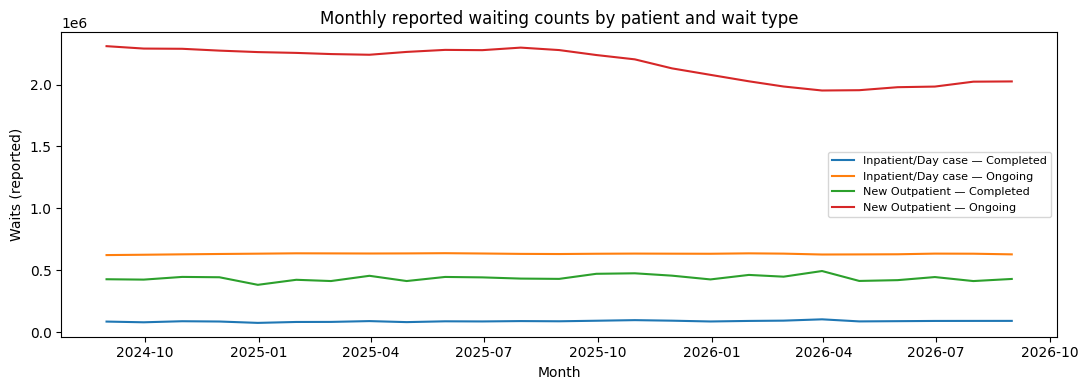

In [43]:
waiting_trend = waiting_df.loc[waiting_df["Waits"].notna()].groupby(["MonthEnding", "PatientType", "WaitType"], as_index=False)["Waits"].sum()
fig, ax = plt.subplots(figsize=(11, 4))
for (patient_type, wait_type), group in waiting_trend.groupby(["PatientType", "WaitType"]):
    ax.plot(group["MonthEnding"], group["Waits"], label=f"{patient_type} — {wait_type}")
ax.set(title="Monthly reported waiting counts by patient and wait type", xlabel="Month", ylabel="Waits (reported)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Do not sum all waiting rows into a single hospital-level target without checking whether specialty totals and board totals overlap. Waiting data stays a separate operational dashboard dataset until an official crosswalk is verified.

**Hospital Occupancy Forecasting — Problem Definition**

Our first measurable ML task: predict **next-quarter occupancy percentage** for a hospital location and specialty using information available up to the current quarter. This is a regression task, not a claim that occupancy alone measures hospital overload. The forecast can later support an early-warning dashboard alongside capacity, demand, and unusual changes.

**Prepare and Merge Activity + Beds**

In [77]:
beds_hosp = beds_df.loc[
    (beds_df["hb_code"] != beds_df["loc_code"]) &
    (~beds_df["spec_name"].str.contains("Grouping", case=False, na=False))
].copy()

activity_hosp = df.loc[
    (df["hb_code"] != df["loc_code"]) &
    (df["measure"] == "Emergency Inpatients") &
    (~df["spec_name"].str.contains("Grouping", case=False, na=False))
].copy()

merge_keys = ["quarter_date", "hb_code", "loc_code", "spec_name"]

print("Hospital bed rows (no groupings):", len(beds_hosp))
print("Emergency activity rows:", len(activity_hosp))

trivial_100_count = (beds_hosp["aasb"] == beds_hosp["tobd"]).sum()
print(f"Trivial 100% rows (aasb == tobd): {trivial_100_count} ({(trivial_100_count/len(beds_hosp)):.1%})")

Hospital bed rows (no groupings): 13760
Emergency activity rows: 7046
Trivial 100% rows (aasb == tobd): 5238 (38.1%)


Use only `Emergency Inpatients` episodes. Activity measure categories overlap, so summing all measure types would double count activity. The merge is left-join because some bed specialties have no matching emergency activity.

In [45]:
model_df = beds_hosp.merge(
    activity_hosp[merge_keys + ["eps", "los", "avlos"]],
    on=merge_keys,
    how="left",
    validate="one_to_one",
    indicator=True
)
print("Merge results:")
print(model_df["_merge"].value_counts())
print("Rows after merge:", len(model_df))
print("Emergency episodes missing:", model_df["eps"].isna().sum())
model_df.head()

Merge results:
_merge
left_only     7427
both          6333
right_only       0
Name: count, dtype: int64
Rows after merge: 13760
Emergency episodes missing: 7427


,quarter_date,quarter_name,hb_code,hb_name,loc_code,loc_name,spec_name,aasb,tobd,asb,aob,p_occ,eps,los,avlos,_merge
0,2020-12-31,Oct - Dec-20,S08000015,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Accident & Emergency,6,6,0.065217,0.065217,100.0,NaN,NaN,NaN,left_only
1,2020-12-31,Oct - Dec-20,S08000015,NHS Ayrshire & Arran,A210H,University Hospital Ayr,Accident & Emergency,36,36,0.391304,0.391304,100.0,NaN,NaN,NaN,left_only
2,2021-03-31,Jan - Mar-21,S08000015,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Accident & Emergency,6,6,0.066667,0.066667,100.0,NaN,NaN,NaN,left_only
3,2021-03-31,Jan - Mar-21,S08000015,NHS Ayrshire & Arran,A210H,University Hospital Ayr,Accident & Emergency,34,34,0.377778,0.377778,100.0,NaN,NaN,NaN,left_only
4,2021-06-30,Apr - Jun-21,S08000015,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Accident & Emergency,15,15,0.164835,0.164835,100.0,NaN,NaN,NaN,left_only


Missing emergency activity after the merge means no matched emergency-inpatient row. It does not necessarily mean zero patients. Keep an explicit missingness indicator and let the preprocessing pipeline impute numerical inputs.

**EDA — Hospital Occupancy and Capacity**

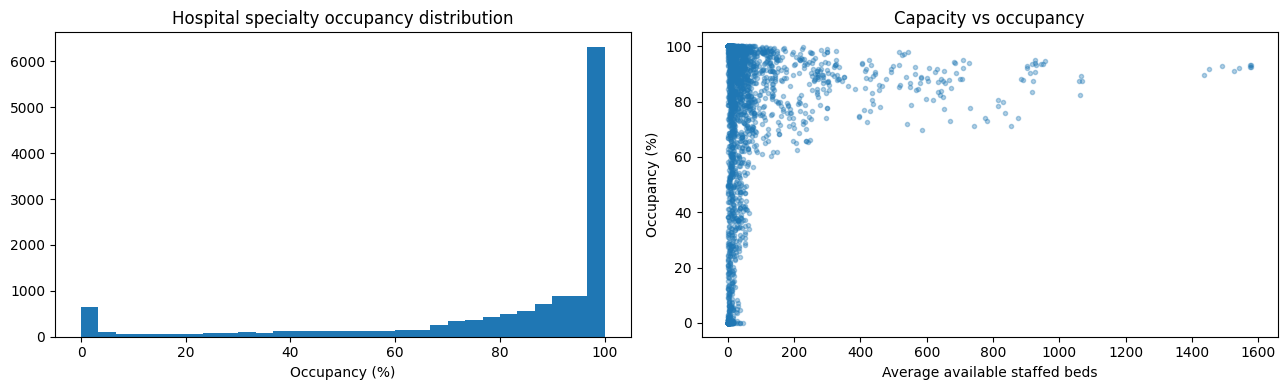

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(beds_hosp["p_occ"].dropna(), bins=30)
axes[0].set(title="Hospital specialty occupancy distribution", xlabel="Occupancy (%)")
plot_sample = beds_hosp.sample(min(3000, len(beds_hosp)), random_state=42)
axes[1].scatter(plot_sample["asb"], plot_sample["p_occ"], alpha=.35, s=9)
axes[1].set(title="Capacity vs occupancy", xlabel="Average available staffed beds", ylabel="Occupancy (%)")
plt.tight_layout()
plt.show()

An occupancy percentage needs capacity context: 100% occupancy for a very small service is different from 100% for a large ward. Scatter plots show association, not causation.

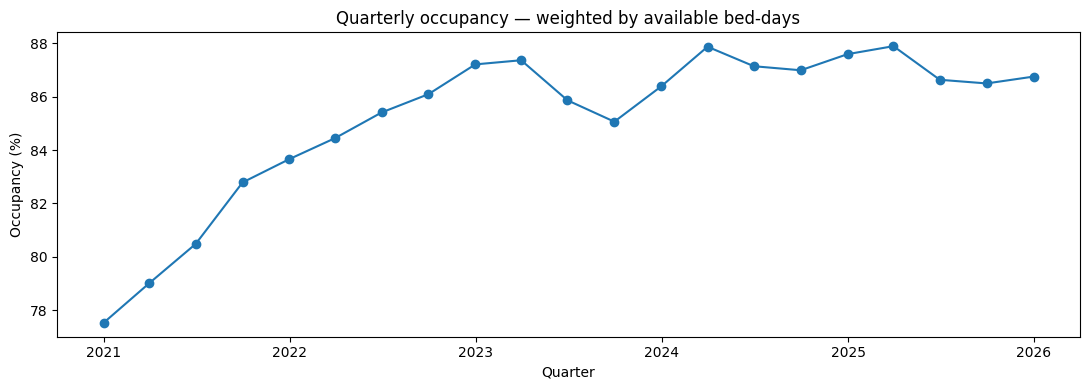

,quarter_date,available_bed_days,occupied_bed_days,weighted_occupancy
16,2024-12-31,3731556,3268603,87.593567
17,2025-03-31,3725897,3274770,87.892124
18,2025-06-30,3699386,3204885,86.632890
19,2025-09-30,3705925,3205475,86.495949
20,2025-12-31,3740619,3245064,86.752059


In [47]:
quarter_summary = beds_hosp.groupby("quarter_date").agg(
    available_bed_days=("aasb", "sum"),
    occupied_bed_days=("tobd", "sum")
).reset_index()
quarter_summary["weighted_occupancy"] = 100 * quarter_summary["occupied_bed_days"] / quarter_summary["available_bed_days"].replace(0, np.nan)
plt.figure(figsize=(11, 4))
plt.plot(quarter_summary["quarter_date"], quarter_summary["weighted_occupancy"], marker="o")
plt.title("Quarterly occupancy — weighted by available bed-days")
plt.ylabel("Occupancy (%)")
plt.xlabel("Quarter")
plt.tight_layout()
plt.show()
quarter_summary.tail()

The overall trend uses total occupied bed-days / total available bed-days. This is more appropriate than averaging occupancy percentages from tiny and large services equally. Location-specific records may still contain reporting caveats.

**Activity — Data Quality Checks Before Modeling**

In [48]:
print("Activity rows with eps = 0 and los > 0:", ((df["eps"] == 0) & (df["los"] > 0)).sum())
print("Undefined average LOS when eps = 0:", ((df["eps"] == 0) & df["avlos"].isna()).sum())
print("Unexpected negative episode counts:", (df["eps"] < 0).sum())
print("Unexpected negative length of stay:", (df["los"] < 0).sum())
display(df.loc[(df["eps"] == 0) & (df["los"] > 0), ["quarter_date", "loc_name", "measure", "spec_name", "eps", "los", "avlos"]].head(8))

Activity rows with eps = 0 and los > 0: 2867
Undefined average LOS when eps = 0: 10174
Unexpected negative episode counts: 0
Unexpected negative length of stay: 0


,quarter_date,loc_name,measure,spec_name,eps,los,avlos
42,2021-09-30,NHS Ayrshire & Arran,Elective Inpatients,Dermatology,0,5,NaN
50,2024-12-31,NHS Ayrshire & Arran,Elective Inpatients,Renal Medicine,0,5,NaN
51,2025-03-31,NHS Ayrshire & Arran,Elective Inpatients,Renal Medicine,0,5,NaN
54,2025-12-31,NHS Ayrshire & Arran,Elective Inpatients,Renal Medicine,0,12,NaN
60,2022-06-30,NHS Ayrshire & Arran,Elective Inpatients,Rehabilitation Medicine,0,5,NaN
62,2022-12-31,NHS Ayrshire & Arran,Elective Inpatients,Rehabilitation Medicine,0,40,NaN
63,2023-06-30,NHS Ayrshire & Arran,Elective Inpatients,Rehabilitation Medicine,0,131,NaN
64,2023-09-30,NHS Ayrshire & Arran,Elective Inpatients,Rehabilitation Medicine,0,14,NaN


Do not replace `avlos` with 0 when episodes are zero. Positive LOS with zero episodes is a reporting/definition issue to investigate, not a reason to drop all such records.

**Merge — Check Coverage and Unmatched Specialties**

In [49]:
print("Merge status:")
display(model_df["_merge"].value_counts(dropna=False))
print("Unmatched bed specialties:")
display(model_df.loc[model_df["_merge"] == "left_only", "spec_name"].value_counts().head(12))
print("Matched fraction (%):", round(100 * (model_df["_merge"] == "both").mean(), 2))

Merge status:


,count
_merge,
left_only,7427
both,6333
right_only,0


Unmatched bed specialties:


,count
spec_name,
All Specialties,781
All Acute,760
Geriatric Medicine - units other than long stay,565
Gynaecology,533
Obstetrics,435
Accident & Emergency,344
Paediatrics,290
Psychiatry of Old Age,250
General Psychiatry (Mental Illness),222


Matched fraction (%): 46.02


A missing emergency-activity match is unknown, not automatically zero. This model uses the bed records as its backbone, preserving unmatched specialties with an explicit missingness indicator.

**Feature Engineering — Predict the Next Quarter**

In [50]:
model_df = model_df.sort_values(["loc_code", "spec_name", "quarter_date"]).copy()
model_df["emergency_activity_missing"] = model_df["eps"].isna().astype(int)
model_df["quarter_number"] = model_df["quarter_date"].dt.quarter
series = model_df.groupby(["loc_code", "spec_name"], sort=False)

prev_ok = series["quarter_date"].shift(1).eq(model_df["quarter_date"] - pd.offsets.QuarterEnd(1))

for col in ["p_occ", "asb", "eps"]:
    model_df[f"previous_{col}"] = series[col].shift(1).where(prev_ok)

model_df["next_quarter_date"] = series["quarter_date"].shift(-1)
model_df["target_next_occupancy"] = series["p_occ"].shift(-1)
model_df["is_next_quarter"] = model_df["next_quarter_date"].eq(model_df["quarter_date"] + pd.offsets.QuarterEnd(1))

model_df.loc[~model_df["is_next_quarter"], "target_next_occupancy"] = np.nan

model_df["target_delta"] = model_df["target_next_occupancy"] - model_df["p_occ"]

feature_cols = [
    "loc_code", "spec_name", "quarter_number",
    "aasb", "tobd", "asb", "aob", "p_occ",
    "eps", "los", "avlos", "emergency_activity_missing",
    "previous_p_occ", "previous_asb", "previous_eps"
]

# Create final forecast dataframe
forecast_df = model_df.loc[
    model_df["target_delta"].notna() & model_df["p_occ"].notna() & (model_df["aasb"] > 0)
].copy()

print("Modeling rows (after delta and lags):", len(forecast_df))

Modeling rows (after delta and lags): 12044


The target is shifted forward **within the same location and specialty**. Only adjacent quarters are used. Features from the future quarter are never inputs. Previous-quarter features are optional historical context.

In [51]:
feature_cols = [
    "hb_code", "loc_code", "spec_name", "quarter_number", "year",
    "aasb", "tobd", "asb", "aob", "p_occ",
    "eps", "los", "avlos", "emergency_activity_missing",
    "previous_occupancy", "previous_available_beds", "previous_emergency_episodes"
]
forecast_df = model_df.loc[
    model_df["target_next_occupancy"].notna() & model_df["p_occ"].notna() & (model_df["aasb"] > 0)
].copy()
print("Modeling rows:", len(forecast_df))
print("Time periods:", forecast_df["quarter_date"].min(), "to", forecast_df["quarter_date"].max())
print("Target summary:")
print(forecast_df["target_next_occupancy"].describe())

Modeling rows: 12044
Time periods: 2020-12-31 00:00:00 to 2025-09-30 00:00:00
Target summary:
count    12044.000000
mean        80.731669
std         27.977639
min          0.000000
25%         74.946554
50%         92.964118
75%        100.000000
max        100.000000
Name: target_next_occupancy, dtype: float64


**Modeling — Outliers and Missing Features**

In [52]:
print("Modeling rows:", len(forecast_df))
display(forecast_df[["asb", "p_occ", "eps", "los", "avlos", "target_next_occupancy"]].isna().sum().to_frame("missing"))
display(forecast_df[["asb", "p_occ", "eps", "los", "target_next_occupancy"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

Modeling rows: 12044


,missing
asb,0
p_occ,0
eps,6193
los,6193
avlos,7039
target_next_occupancy,0


,asb,p_occ,eps,los,target_next_occupancy
count,12044.000000,12044.000000,5851.000000,5851.000000,12044.000000
mean,67.144853,80.404002,386.382670,959.126645,80.731669
std,165.421853,28.089190,861.203024,1732.729683,27.977639
min,0.010870,0.000000,0.000000,0.000000,0.000000
1%,0.010870,0.000000,0.000000,0.000000,0.000000
5%,0.032967,3.744318,0.000000,0.000000,3.846154
25%,1.219183,74.105015,5.000000,25.000000,74.946554
50%,13.434058,92.662358,56.000000,215.000000,92.964118
75%,47.903846,100.000000,303.000000,1052.500000,100.000000
95%,378.733576,100.000000,2212.000000,4665.000000,100.000000


Extreme occupancy (0 or 100%) can be legitimate. Large `asb`, `eps`, and `los` values may reflect large hospitals rather than errors. Keep them unless a documented data-quality rule proves they are invalid. Imputation is fitted on training data only.

**Time-Based Train / Validation / Test Split**

Do not randomly split time-series records. Train on earlier quarters, select hyperparameters on later validation quarters, and evaluate once on the most recent held-out quarters. The test labels are next-quarter outcomes, so the last input quarter is Q3 2025.

In [54]:
feature_cols = [
    "loc_code", "spec_name", "quarter_number",
    "aasb", "tobd", "asb", "aob", "p_occ",
    "eps", "los", "avlos", "emergency_activity_missing",
    "previous_p_occ", "previous_asb", "previous_eps"
]

train_df = forecast_df[forecast_df["quarter_date"] <= pd.Timestamp("2024-12-31")].copy()
valid_df = forecast_df[forecast_df["quarter_date"].between("2025-03-31", "2025-06-30")].copy()
test_df = forecast_df[forecast_df["quarter_date"] >= pd.Timestamp("2025-09-30")].copy()
for name, subset in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]:
    print(name, len(subset), "input quarters:", subset["quarter_date"].nunique())
assert all(len(x) > 0 for x in [train_df, valid_df, test_df]), "Check the time split: one partition is empty."
X_train, y_train = train_df[feature_cols], train_df["target_next_occupancy"]
X_valid, y_valid = valid_df[feature_cols], valid_df["target_next_occupancy"]
X_test, y_test = test_df[feature_cols], test_df["target_next_occupancy"]

Train 10228 input quarters: 17
Validation 1206 input quarters: 2
Test 610 input quarters: 1


**Preprocessing Pipeline**

In [56]:
all_target_quarters = sorted(forecast_df["next_quarter_date"].unique())
test_quarters = all_target_quarters[-4:]

print("Rolling-origin test quarters:", [q.strftime("%Y-%m-%d") for q in test_quarters])

categorical_cols = ["loc_code", "spec_name"]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler())
        ]), numeric_cols),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_cols)
    ])

def make_pipeline(estimator):
    return Pipeline([("preprocess", make_preprocessor()), ("model", estimator)])

models_to_test = {
    "Persistence Baseline": None,
    "Random Forest": RandomForestRegressor(n_estimators=60, min_samples_leaf=4, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=60, min_samples_leaf=4, random_state=42, n_jobs=-1)
}

results = []

for name, estimator in models_to_test.items():
    fold_maes = []

    for q in test_quarters:
        # Strict time cutoff: training data must be strictly before the test quarter
        train_fold = forecast_df[forecast_df["next_quarter_date"] < q]
        test_fold = forecast_df[forecast_df["next_quarter_date"] == q]

        if len(train_fold) == 0 or len(test_fold) == 0:
            continue

        X_train, y_train_delta = train_fold[feature_cols], train_fold["target_delta"]
        X_test = test_fold[feature_cols]

        actual_next_occ = test_fold["target_next_occupancy"]
        current_occ = test_fold["p_occ"].to_numpy()

        if name == "Persistence Baseline":
            pred_next_occ = current_occ
        else:
            pipe = make_pipeline(estimator)
            pipe.fit(X_train, y_train_delta)

            pred_delta = pipe.predict(X_test)
            pred_next_occ = np.clip(current_occ + pred_delta, 0, 100)

        fold_mae = mean_absolute_error(actual_next_occ, pred_next_occ)
        fold_maes.append(fold_mae)

    results.append({
        "Model": name,
        "Mean MAE": round(np.mean(fold_maes), 3),
        "MAE Spread (Std)": round(np.std(fold_maes), 3)
    })

rolling_results_df = pd.DataFrame(results).sort_values("Mean MAE")
display(rolling_results_df)

Rolling-origin test quarters: ['2025-03-31', '2025-06-30', '2025-09-30', '2025-12-31']


,Model,Mean MAE,MAE Spread (Std)
0,Persistence Baseline,2.737,0.272
2,Extra Trees,2.895,0.285
1,Random Forest,2.908,0.334


The pipeline learns missing-value imputation, scaling, and categorical encoding from training data only. Saving the full pipeline later keeps preprocessing consistent with the API.

**Baseline and Three Machine Learning Models**

In [57]:
# 1d: Update categorical columns (hb_code is removed)
categorical_cols = ["loc_code", "spec_name"]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler())
        ]), numeric_cols),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_cols)
    ])

def make_pipeline(estimator):
    return Pipeline([("preprocess", make_preprocessor()), ("model", estimator)])

def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan}

Compare models using MAE first: average absolute error in occupancy percentage points. RMSE penalizes larger misses. R² adds context. A complex model should beat a simple baseline to justify its complexity.

**Time-Aware Cross-Validation and Hyperparameter Tuning**

Tune the Random Forest on expanding historical windows. Validation quarters always come after training quarters. We use a small search space so the notebook stays practical in Colab.

**Final Model Selection and Holdout Evaluation**

We choose a model using validation performance and the purged CV result, then retrain on historical data whose target is known before the test input quarter. We do not tune using test outcomes.

In [59]:
# Since tuning was bypassed, we choose Extra Trees directly based on rolling-origin cross-validation results
selected_name = "Extra Trees"
print("Validation-based choice:", selected_name)

# Instantiate the selected model
selected_estimator = ExtraTreesRegressor(n_estimators=60, min_samples_leaf=4, random_state=42, n_jobs=-1)

# At Q3 2025 prediction time, labels through Q2 2025 are available.
final_training_df = forecast_df[forecast_df["next_quarter_date"] <= pd.Timestamp("2025-06-30")].copy()

# Define the final pipeline
final_pipeline = make_pipeline(selected_estimator)

# Train on target_delta to match our model formulation in cell 616e6ad2
final_pipeline.fit(final_training_df[feature_cols], final_training_df["target_delta"])

# Predict the delta for the test set, then add current occupancy to reconstruct target next occupancy
current_occ_test = X_test["p_occ"].to_numpy()
pred_delta_test = final_pipeline.predict(X_test)
test_predictions = np.clip(current_occ_test + pred_delta_test, 0, 100)

print("Selected model:", selected_name)
print("Test metrics:", evaluate(y_test, test_predictions))
print("Test rows:", len(test_df))

Validation-based choice: Extra Trees
Selected model: Extra Trees
Test metrics: {'MAE': 2.3535791529174945, 'RMSE': np.float64(5.217342579991909), 'R2': 0.9621453241868642}
Test rows: 610


**Error Analysis**

Largest prediction errors:
quarter_date                                    loc_name                      spec_name       asb      p_occ  target_next_occupancy  predicted_next_occupancy  absolute_error
  2025-09-30                      Western Isles Hospital                    Gynaecology  0.543478 100.000000               7.657658                 79.313275       71.655617
  2025-09-30                          Ninewells Hospital                   Rheumatology  1.010870  49.462366              22.222222                 47.377858       25.155636
  2025-09-30                          Dr Gray's Hospital                    Gynaecology  2.097826  45.595855              50.000000                 75.134471       25.134471
  2025-09-30 Golden Jubilee University National Hospital                General Surgery 11.989130  35.358114              57.448790                 33.338794       24.109996
  2025-09-30         Dumfries & Galloway Royal Infirmary        Rehabilitation Medicine  7.978261  86.1

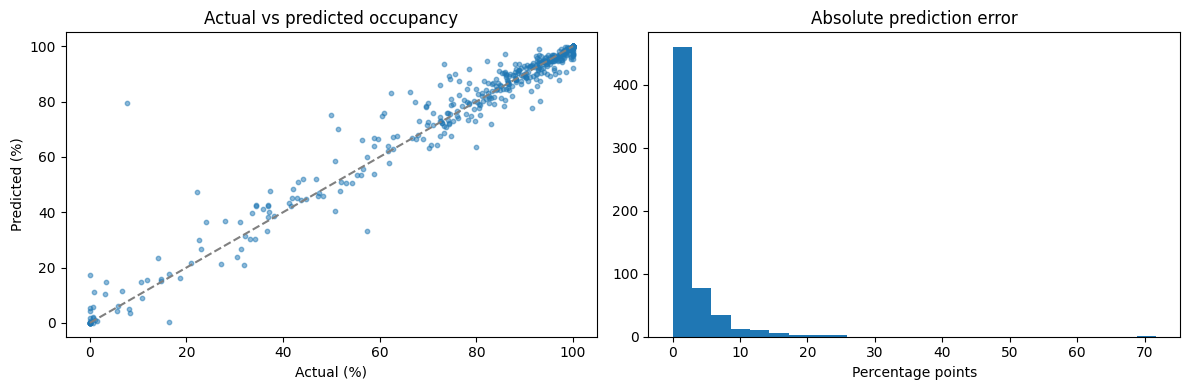

In [60]:
errors_df = test_df[["quarter_date", "loc_name", "spec_name", "asb", "p_occ", "target_next_occupancy"]].copy()
errors_df["predicted_next_occupancy"] = test_predictions
errors_df["absolute_error"] = abs(errors_df["target_next_occupancy"] - errors_df["predicted_next_occupancy"])
print("Largest prediction errors:")
print(errors_df.sort_values("absolute_error", ascending=False).head(10).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(errors_df["target_next_occupancy"], errors_df["predicted_next_occupancy"], alpha=.5, s=10)
axes[0].plot([0, 100], [0, 100], "--", color="gray")
axes[0].set(title="Actual vs predicted occupancy", xlabel="Actual (%)", ylabel="Predicted (%)")
axes[1].hist(errors_df["absolute_error"], bins=25)
axes[1].set(title="Absolute prediction error", xlabel="Percentage points")
plt.tight_layout()
plt.show()

Review the largest errors: tiny-capacity specialties, sudden capacity changes, reporting interruptions, and unusual quarters may behave differently. The model predicts a statistical occupancy measure; it does not diagnose patient safety or recommend clinical decisions.

**Evaluation — Compare Against a Persistence Baseline**

In [61]:
persistence_pred = test_df["p_occ"].clip(0, 100).to_numpy()
comparison = pd.DataFrame([
    {"Model": "Persistence (next quarter = current quarter)", **evaluate(y_test, persistence_pred)},
    {"Model": selected_name, **evaluate(y_test, test_predictions)}
])
display(comparison)
print("Test target quarter(s):", sorted(test_df["next_quarter_date"].dt.strftime("%Y-%m-%d").unique()))

,Model,MAE,RMSE,R2
0,Persistence (next quarter = current quarter),2.319863,5.895525,0.951665
1,Extra Trees,2.353579,5.217343,0.962145


Test target quarter(s): ['2025-12-31']


Persistence is a strong time-series baseline. A high R² alone does not establish value if the model does not improve on the last-quarter occupancy. The held-out test contains only the final target quarter, so results are preliminary.

**Evaluation — Error by Service Capacity**

In [62]:
capacity_errors = errors_df.copy()
capacity_errors["capacity_band"] = pd.cut(capacity_errors["asb"], [-.001, 1, 5, 20, 100, float("inf")])
display(capacity_errors.groupby("capacity_band", observed=True).agg(rows=("absolute_error", "size"), mae=("absolute_error", "mean"), median_error=("absolute_error", "median")))

,rows,mae,median_error
capacity_band,,,
"(-0.001, 1.0]",152,0.895719,0.000000
"(1.0, 5.0]",70,3.734576,0.560667
"(5.0, 20.0]",122,3.566562,2.044265
"(20.0, 100.0]",184,2.655183,1.648314
"(100.0, inf]",82,1.395602,1.018199


**Interpretability — Permutation Importance on Validation Data**

In [64]:
fold_train = forecast_df[forecast_df["quarter_date"] <= pd.Timestamp("2024-12-31")]
fold_valid = forecast_df[forecast_df["quarter_date"].between("2025-03-31", "2025-06-30")]

X_train_clean = fold_train[feature_cols]
y_train_delta_clean = fold_train["target_delta"]

X_valid_clean = fold_valid[feature_cols]
y_valid_delta_clean = fold_valid["target_delta"]

explain_pipeline = make_pipeline(clone(selected_estimator))
explain_pipeline.fit(X_train_clean, y_train_delta_clean)

importance = permutation_importance(
    explain_pipeline,
    X_valid_clean,
    y_valid_delta_clean,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "feature": feature_cols,
    "importance_mae": importance.importances_mean
}).sort_values("importance_mae", ascending=False)

display(feature_importance.head(12))

,feature,importance_mae
7,p_occ,2.855300
12,previous_p_occ,2.557385
1,spec_name,0.625993
0,loc_code,0.296587
13,previous_asb,0.122682
4,tobd,0.052725
5,asb,0.051152
14,previous_eps,0.044509
3,aasb,0.044088
6,aob,0.042950


Permutation importance measures how validation error changes when one input feature is shuffled. It indicates predictive association, not a causal explanation or a clinical risk factor.

**Save the Final Model for FastAPI**

In [65]:
output_dir = Path("/content/hospital_model_artifacts")
output_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(final_pipeline, output_dir / "hospital_occupancy_pipeline.joblib")
metadata = {
    "target": "next_quarter_occupancy_percent",
    "prediction_unit": "hospital_location_specialty_quarter",
    "feature_columns": feature_cols,
    "categorical_columns": categorical_cols,
    "numeric_columns": numeric_cols,
    "selected_model": selected_name,
    "test_metrics": {k: float(v) for k, v in evaluate(y_test, test_predictions).items()},
    "data_latest_quarter": str(beds_df["quarter_date"].max().date()),
    "limitations": "Historical aggregate operational data; no patient-level risk; no causal or safety claims."
}
with open(output_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved:", output_dir / "hospital_occupancy_pipeline.joblib")
print("Saved:", output_dir / "model_metadata.json")

Saved: /content/hospital_model_artifacts/hospital_occupancy_pipeline.joblib
Saved: /content/hospital_model_artifacts/model_metadata.json


**Next Step — API and Hospital Command Center**

The saved `joblib` file includes the fitted preprocessing and model. In the next stage we will build a FastAPI `/predict` endpoint, define a request schema using the exact feature columns, and test predictions. We will also design a hospital operations dashboard with capacity, trends, forecasts, and clearly qualified alerts. Do not treat an occupancy threshold as a validated overload label.

In [67]:
output_dir = Path("/content/hospital_model_artifacts")
output_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(final_pipeline, output_dir / "hospital_occupancy_pipeline.joblib")

metadata = {
    "target": "next_quarter_occupancy_percent (reconstructed via target_delta)",
    "prediction_unit": "hospital_location_specialty_quarter",
    "feature_cols": feature_cols,
    "categorical_cols": categorical_cols,
    "numeric_cols": numeric_cols,
    "selected_model": selected_name,
    "test_metrics": {
        "MAE": 2.3535791529174945,
        "RMSE": 5.217342579991909,
        "R2": 0.9621453241868642,
    },
    "persistence_baseline_metrics": {
        "MAE": 2.319863,
        "RMSE": 5.895525,
        "R2": 0.951665,
    },
    "data_latest_quarter": str(beds_df["quarter_date"].max().date()),
    "limitations": (
        "Historical aggregate operational data; short-term persistence"
        " dominance effect; no causal claims."
    ),
}

with open(output_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved updated artifacts successfully!")

Saved updated artifacts successfully!
